In [24]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys # Access the Python import path.

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
import numpy as np
from IPython.display import display

In [26]:
residual_dir = repo_root / "data" / "residual"
disk_scale_file = residual_dir / "test_multienergy_residual_products.hdf5"

In [27]:
observed = Histogram.open(
    disk_scale_file,
    name="observed",
)

expected = Histogram.open(
    disk_scale_file,
    name="total_expectation",
)

In [28]:
# Show the dimensions available in the observed histogram.
print(observed.axes.labels)

['Em' 'Phi' 'PsiChi']


In [29]:
# Inspect the measured-energy binning without selecting a bin yet.
em_axis = observed.axes["Em"]

print("Number of Em bins:", em_axis.nbins)
print("Em bin edges:", em_axis.edges)

Number of Em bins: 3
Em bin edges: [300. 400. 600. 800.] keV


In [30]:
# Confirm that observed and expected data have identical dimensions.
print("Observed shape:", observed.shape)
print("Expected shape:", expected.shape)
print("Expected axes:", expected.axes.labels)

Observed shape: (3, 60, 3072)
Expected shape: (3, 60, 3072)
Expected axes: ['Em' 'Phi' 'PsiChi']


In [ ]:
# Create the residual analysis from the full multi-energy histograms.
analysis = ResidualAnalysis(observed, expected)

# Retrieve the energy and energy-resolved CDS projections.
energy_resolved_products = analysis.projected_data()
em_products = energy_resolved_products["Em_projection"]

print("Available projections:", list(energy_resolved_products))
print("Em shape:", em_products["observed"].shape)
print("Observed counts per Em bin:", em_products["observed"].contents)
print("Expected counts per Em bin:", em_products["expected"].contents)

In [32]:
# Calculate residuals after aggregating Phi and PsiChi within each Em bin.
em_raw_residual = analysis.residual_function(
    "Em_projection",
    residual_type="raw",
)

print("Raw residuals per Em bin:", em_raw_residual.contents)

Raw residuals per Em bin: [-1218.06835157 -1598.71296916 -1537.95340144]


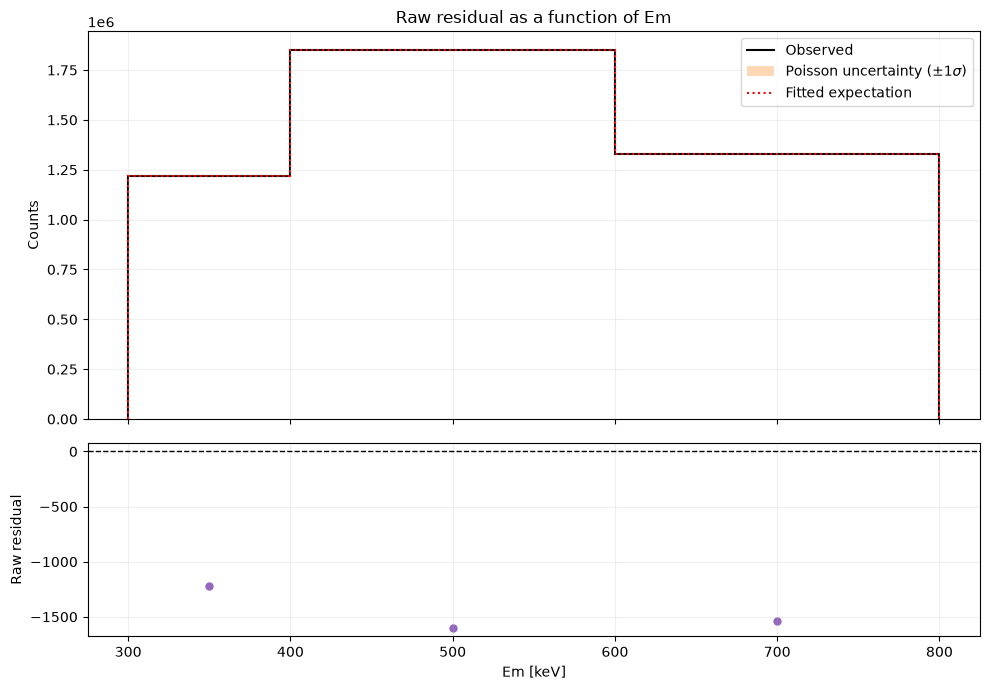

In [33]:
# Configure a reproducible Poisson reference for energy residuals.
residual_plots = PlottingResiduals(
    analysis,
    n_simulations=200,
    random_seed=42,
)

em_raw_figure = residual_plots.plot(
    "Em_projection",
    residual_type="raw",
)

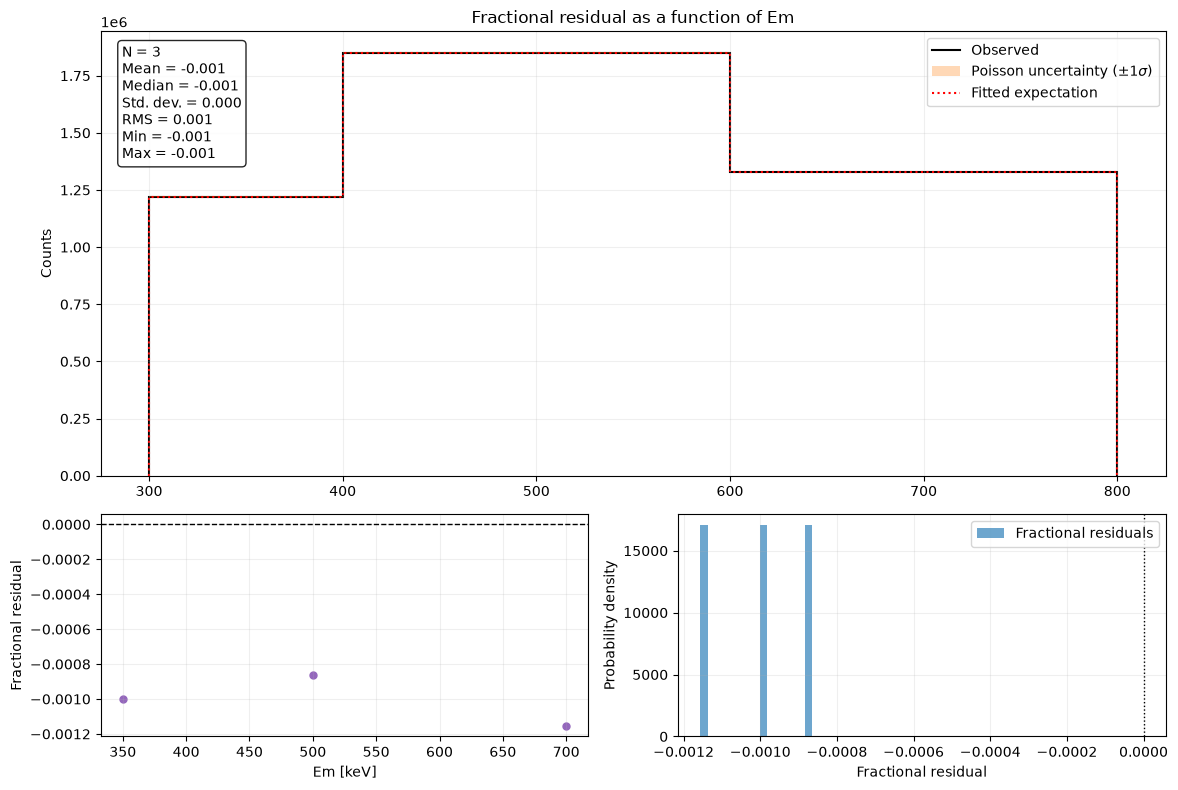

In [34]:
# Plot fractional residuals after aggregating CDS counts within each Em bin.
em_fractional_figure = residual_plots.plot(
    "Em_projection",
    residual_type="fractional",
)

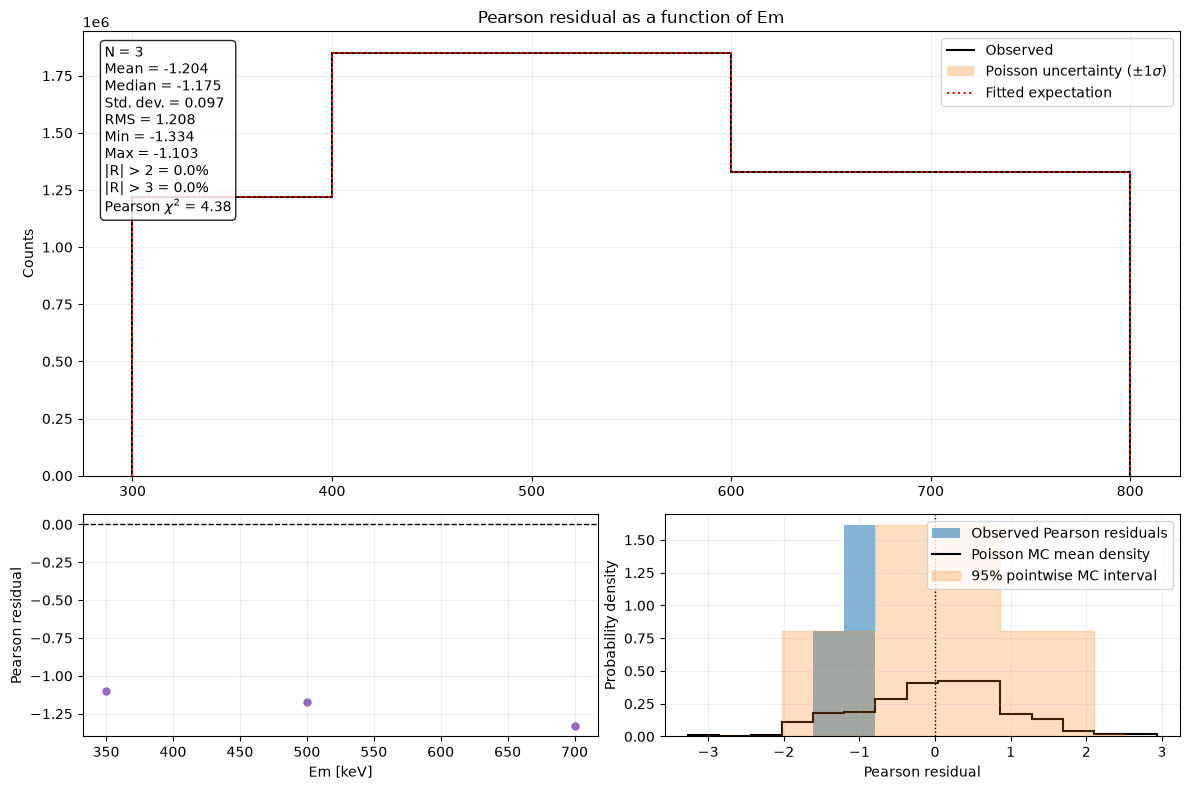

In [35]:

# Plot Pearson residuals for the aggregated counts in each Em bin.
em_pearson_figure = residual_plots.plot(
    "Em_projection",
    residual_type="pearson",
)


## Select a measured-energy interval for CDS diagnostics

The full analysis retains `Em` in its energy-resolved CDS projections. Selecting an interval whose limits match existing `Em` bin edges provides the complementary energy-integrated analysis. The selected interval may contain one or multiple bins, which are aggregated before the residual analysis.

In [ ]:
# Select an exact measured-energy interval for CDS analysis.
energy_min = 600.0
energy_max = 800.0

selected_analysis = analysis.select_energy_range(energy_min, energy_max)

print(
    "Selected energy interval:",
    f"{energy_min:g} keV",
    "to",
    f"{energy_max:g} keV",
)
print("Selected axes:", selected_analysis.observed_hist.axes.labels)
print("Selected shape:", selected_analysis.observed_hist.shape)

In [ ]:
# Confirm that every CDS projection preserves the selected-range counts.
selected_products = selected_analysis.projected_data()
selected_observed_total = float(selected_analysis.observed_hist.contents.sum())
selected_expected_total = float(selected_analysis.expected_hist.contents.sum())

for products in selected_products.values():
    np.testing.assert_allclose(
        products["observed"].contents.sum(),
        selected_observed_total,
    )
    np.testing.assert_allclose(
        products["expected"].contents.sum(),
        selected_expected_total,
    )

print("All CDS projections preserve the selected-range counts.")

In [38]:
# Display Pearson statistics for only the selected energy interval.
display(selected_analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.00287,-0.051165,0.972423,0.972427,-3.182515,18.098258,3.967014,0.564236,174295.639824,171908.606811


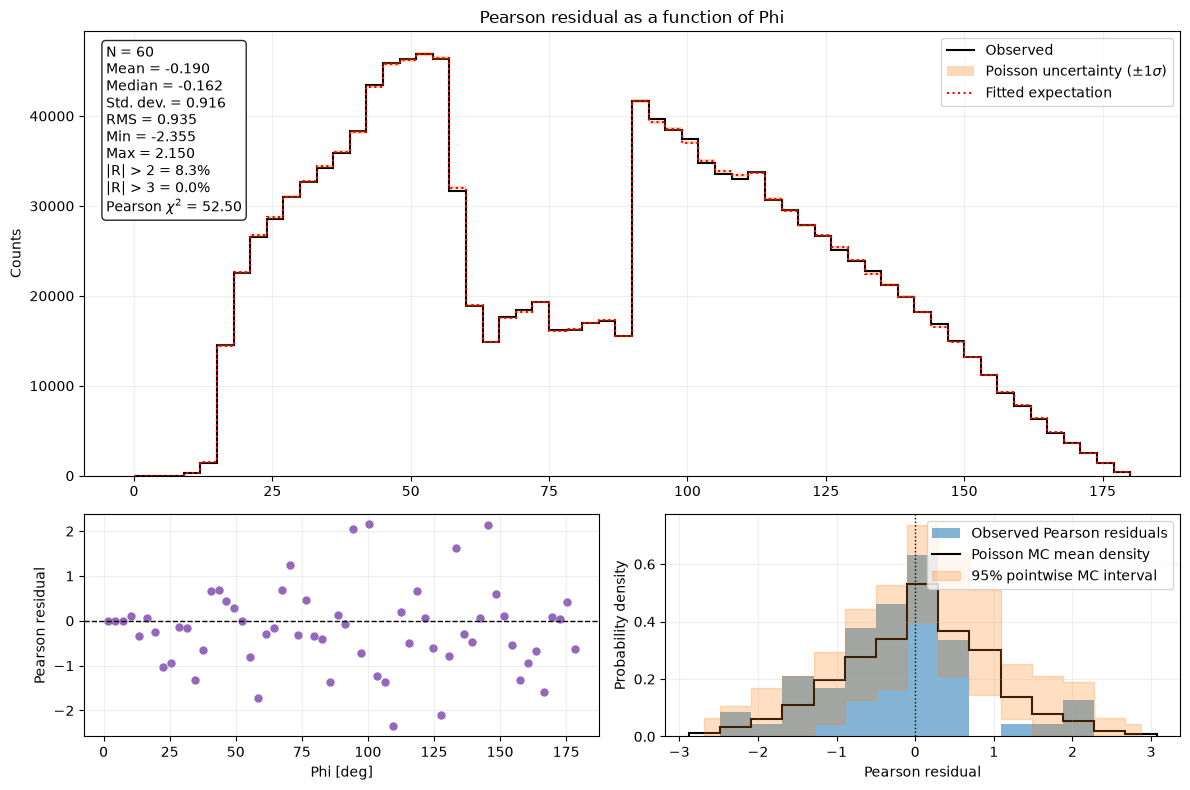

In [39]:
# Use a small reproducible Poisson reference for this CDS pipeline check.
selected_plots = PlottingResiduals(
    selected_analysis,
    n_simulations=20,
    random_seed=42,
)
selected_phi_pearson_figure = selected_plots.plot(
    "Phi_projection",
    residual_type="pearson",
)

In [ ]:
# Verify the Poisson reference for the same selected energy interval.
selected_phi_reference = selected_analysis.pearson_poisson_reference(
    "Phi_projection",
    n_simulations=20,
    bins=15,
    seed=42,
)

np.testing.assert_allclose(
    np.sum(
        selected_phi_reference["density"]
        * np.diff(selected_phi_reference["bin_edges"])
    ),
    1.0,
)
print("The selected-range Poisson reference is normalized.")

In [ ]:
energy_min = 400.0
energy_max = 600.0
selected_analysis = analysis.select_energy_range(energy_min, energy_max)

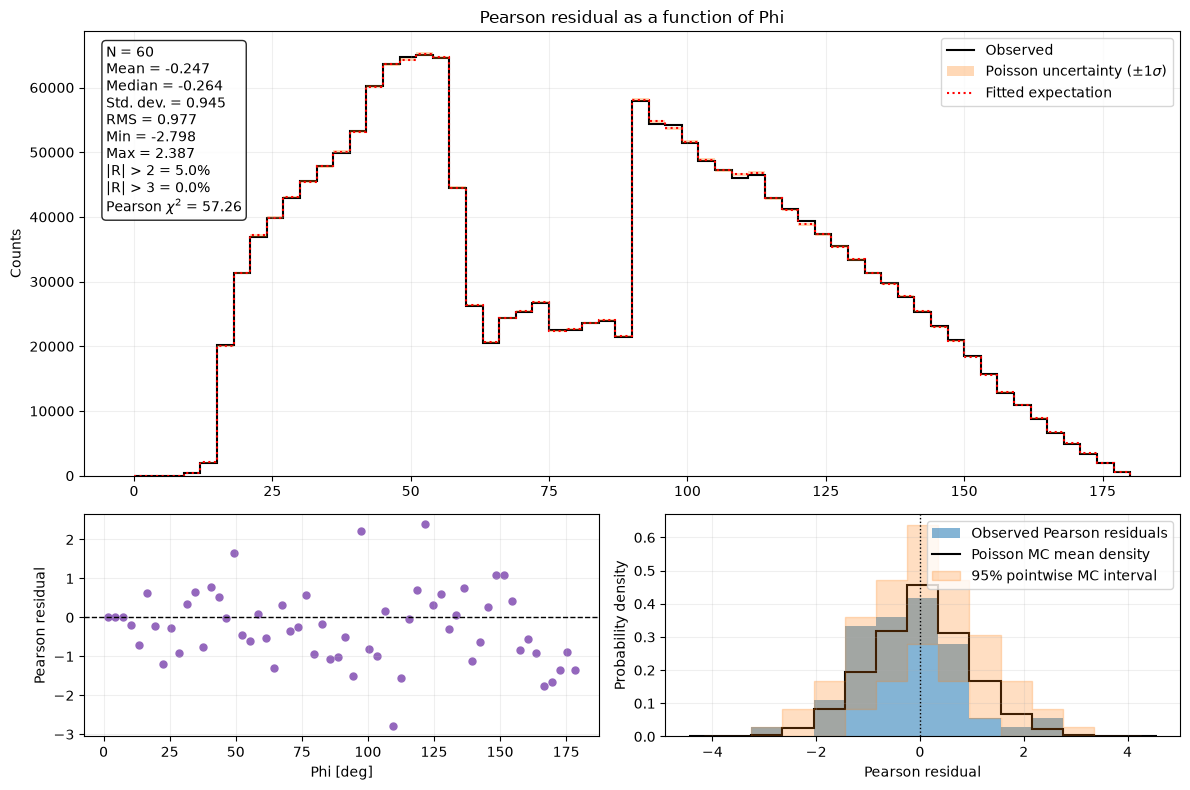

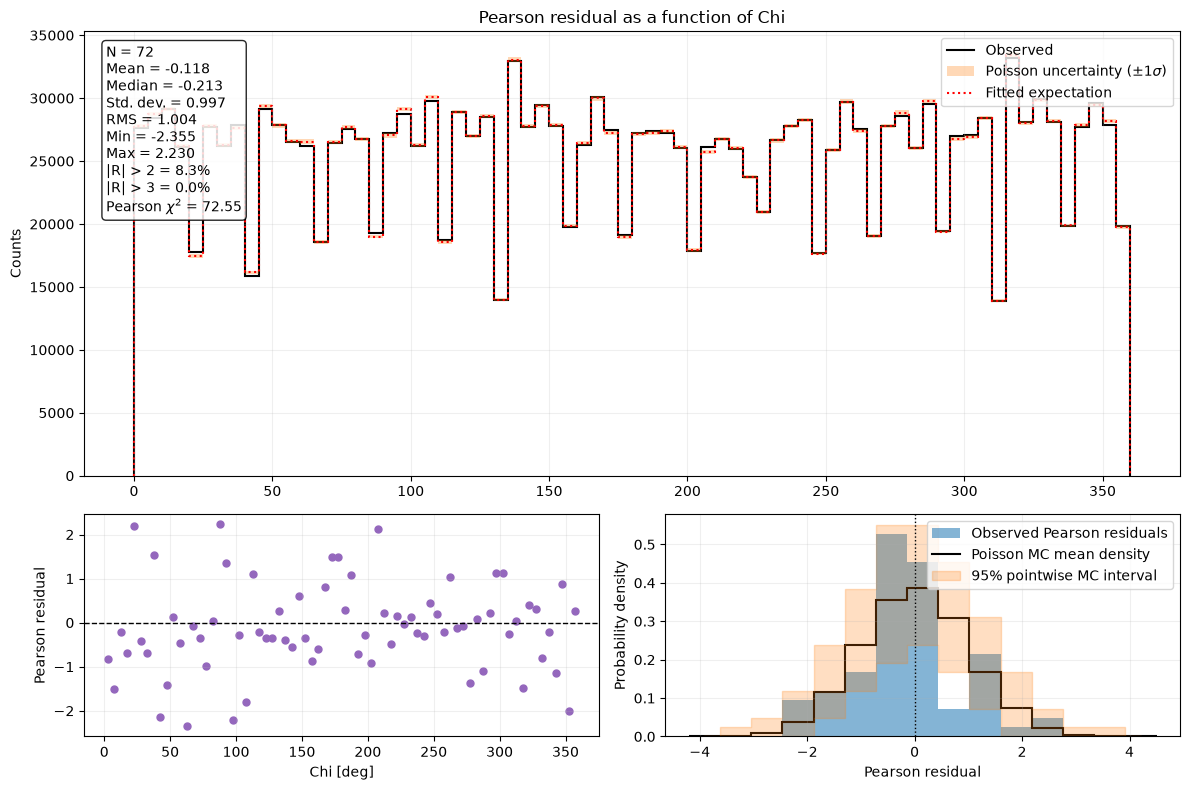

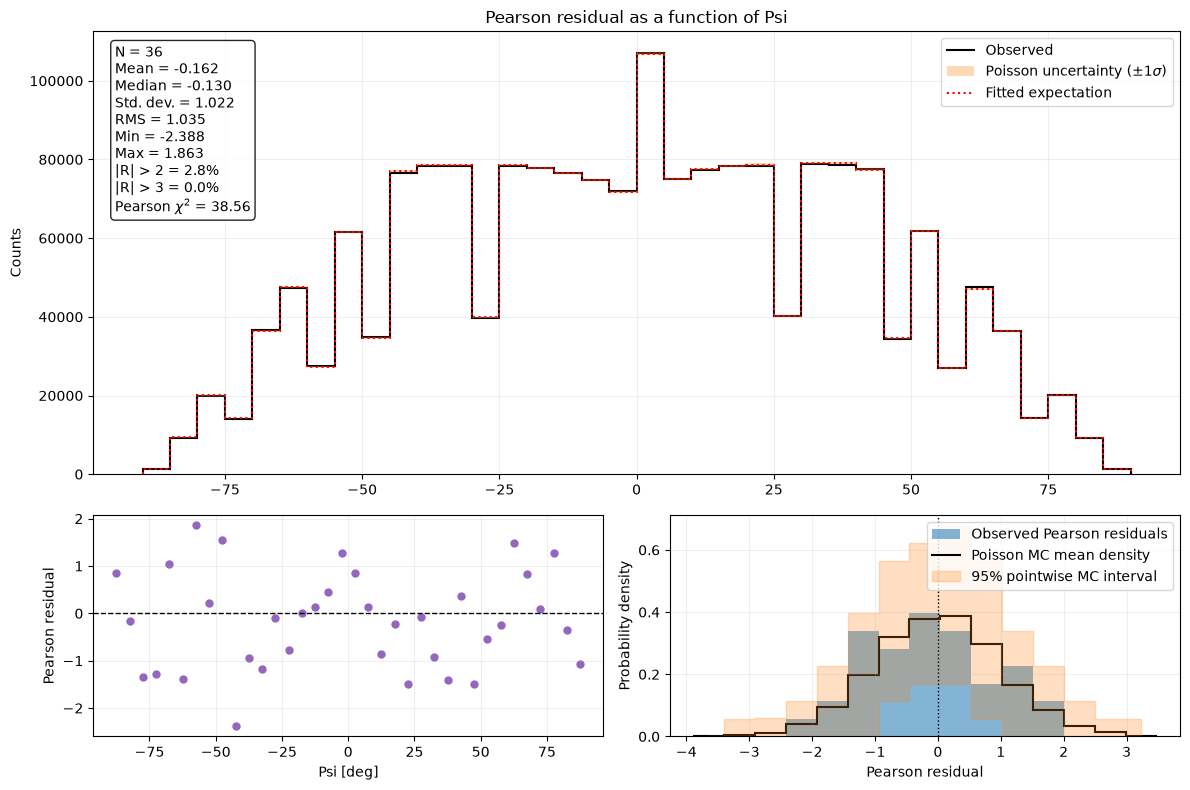

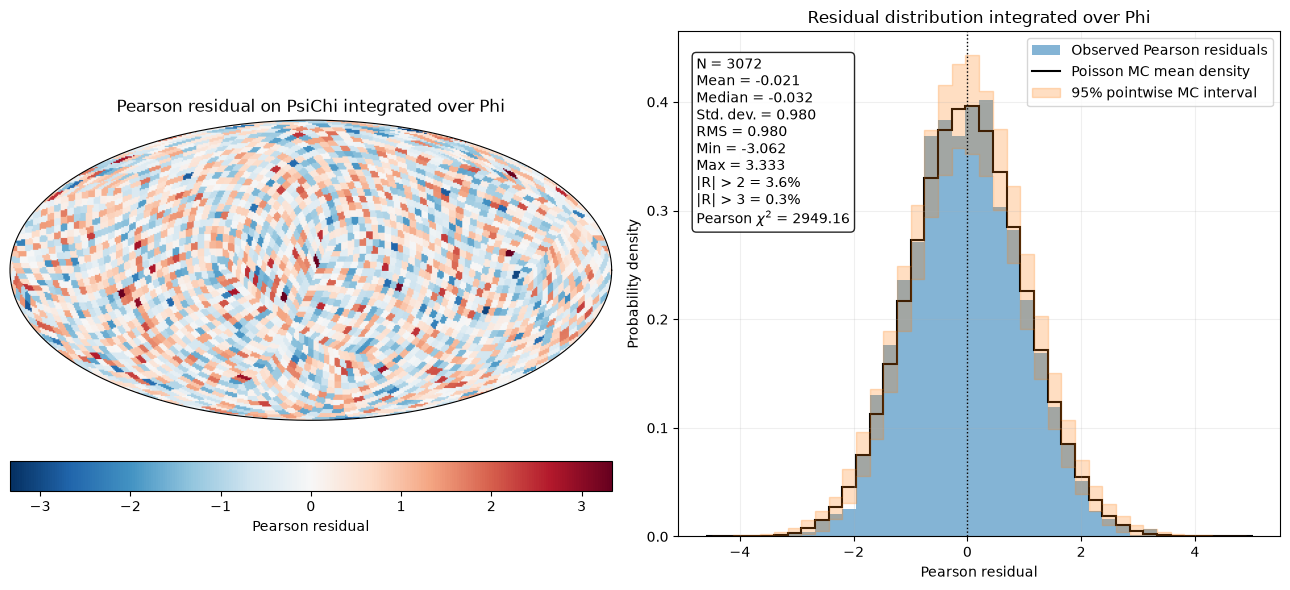

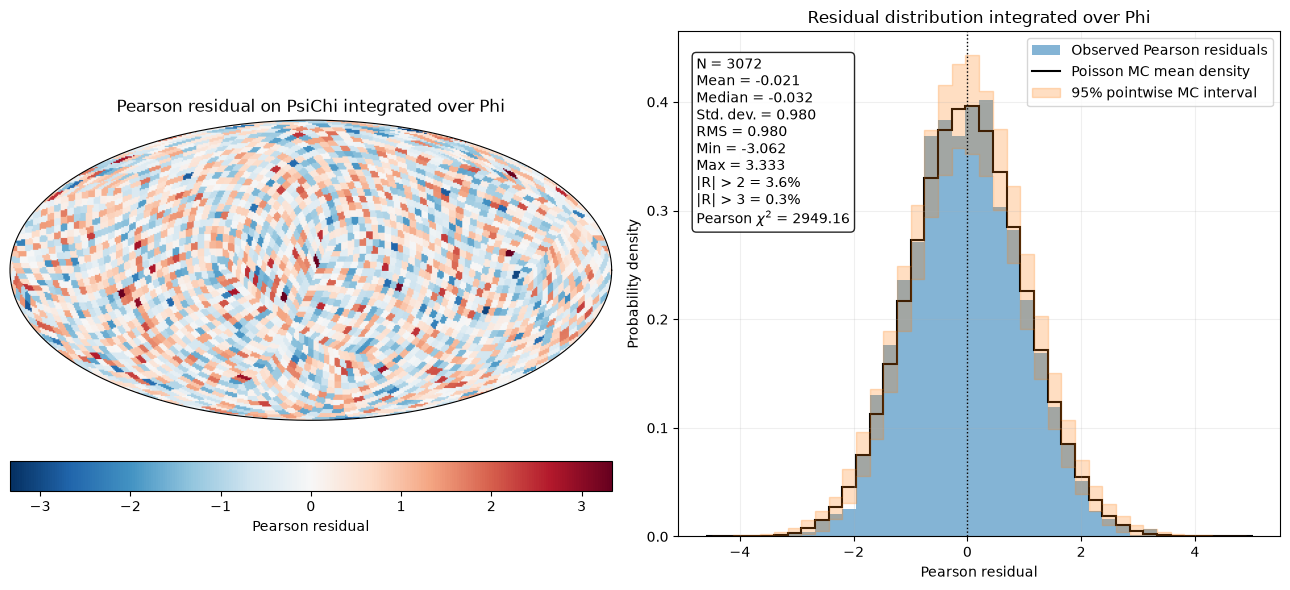

In [44]:
selected_plots = PlottingResiduals(selected_analysis, n_simulations=200, random_seed=42)

selected_plots.plot("Phi_projection", residual_type="pearson")
selected_plots.plot("Chi_projection", residual_type="pearson")
selected_plots.plot("Psi_projection", residual_type="pearson")
selected_plots.plot("PsiChi_projection", residual_type="pearson")